## Podstawowe operacje

W ramach kursu będziemy wykorzystywać głównie bibliotekę OpenCV (Open Computer Vision Library).
W trakcie niniejszego ćwiczenia zapoznamy się z podstawowymi funkcjonalnościami: wczytywaniem, zapisywaniem i konwersją do innej przestrzeni barw.
Zaznajomimy się również z Jupyter Notebook.


**Jak pracować z notebookiem:** komórki wykonujemy kolejno (`Shift+Enter`). Zmienne zdefiniowane w jednej komórce są widoczne w następnych, dlatego komórki należy uruchamiać w kolejności od góry do dołu.

Wczytywanie obrazów z wykorzystaniem OpenCV.
1. Zaimportuj bibliotekę OpenCV:
        `import cv2`
1. Zaimportuj bibliotekę pyplot z matplotlib jako plt:
        `from matplotlib import pyplot as plt`
1. Wygodną opcją jest możliwość pobierania danych (obrazów, ale też np. baz danych) z sieci.
   Eliminuje to konieczność pobierania danych np. z Moodle oraz czyni uzupełniony Notebook "samowystarczalnym" - wystarczy go uruchomić.
   * zaimportuj bibliotekę os `import os`
   * zaimportuj bibliotekę requests `import requests`
   * stwórz zmienne na adres pobieranego pliku (*url*) i samą jego nazwę (*fileName*)
   * sprawdź, czy taki plik istnieje (unikniemy wielokrotnego pobierania tych samych danych)
        `if not os.path.exists(fileName) :`
   * pobierz plik: `r = requests.get(url + fileName, allow_redirects=True)`
   * sprawdź, czy pobieranie się powiodło: `r.raise_for_status()`
   * zapisz na dysku: `with open(fileName, 'wb') as f: f.write(r.content)`

1. Wykorzystując polecenie *imread* wczytaj obraz *mandril.jpg*
1. Wyświetl obraz wykorzystując bibliotekę *pyplot*
        plt.imshow(I)
        plt.xticks([]), plt.yticks([])
        plt.show()
1. Jeśli kolory mandryla wyglądają nienaturalnie (np. niebieski nos zamiast czerwonego), to nie jest to błąd w obrazie.
   Przyczyną jest sposób w jaki funkcja `imread` z OpenCV odczytuje obraz (kolejność kanałów BGR, zamiast RGB, której oczekuje matplotlib).
   Obrazom kolorowym będzie poświęcone odrębne ćwiczenie, więc nie będziemy w tym miejscu rozwijać tego wątku.
1. W celu poprawnego wyświetlenia należy dokonać konwersji koloru z BGR na RGB.
        I = cv2.cvtColor(I, cv2.COLOR_BGR2RGB)
1. Dla porządku warto dodać, że w OpenCV do wyświetlania domyślnie wykorzystuje się funkcję `cv2.imshow`.
   Jednakże w przypadku Jupyter Notebook to rozwiązanie ma pewne wady (okno poza notebookiem, problemy z zamknięciem) i dlatego nie będziemy jej używać.
   Natomiast jeśli ktoś pracuje w "czystym" Pythonie, to jest to na pewno równoważna funkcjonalność.


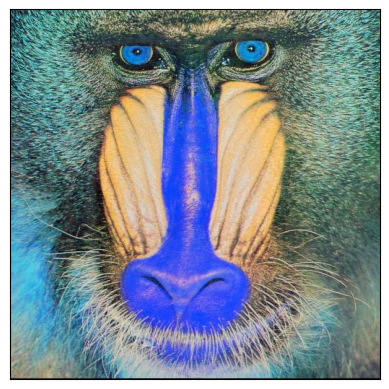

In [1]:
import cv2
import os
from matplotlib import pyplot as plt
import requests
import numpy as np

url = 'https://raw.githubusercontent.com/vision-agh/poc_sw/master/01_Intro/'
fileName = 'mandril.jpg'
if not os.path.exists(fileName) :
    r = requests.get(url + fileName, allow_redirects=True)
    r.raise_for_status()                      # Przerywa, jesli pobieranie sie nie powiodlo
    with open(fileName, 'wb') as f:
        f.write(r.content)

I = cv2.imread(fileName)
plt.imshow(I)
plt.xticks([]), plt.yticks([])  # to hide tick values on X and Y axis
plt.show()

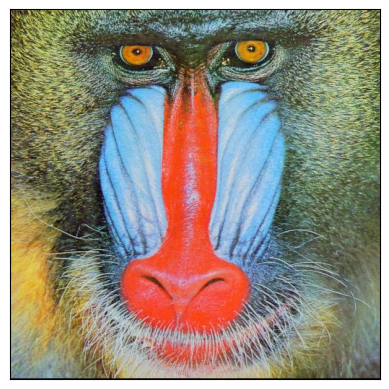

In [2]:
I = cv2.cvtColor(I, cv2.COLOR_BGR2RGB)
plt.imshow(I)
plt.xticks([]), plt.yticks([])  # to hide tick values on X and Y axis
plt.show()

Obraz jest zwykłą tablicą *numpy*. Sprawdź jego rozmiar (`I.shape`), typ danych (`I.dtype`) oraz zakres wartości (`I.min()`, `I.max()`).
Co oznaczają kolejne liczby w `I.shape`? Który wymiar to wysokość, a który szerokość obrazu?

In [3]:
print('shape:', I.shape)                       # (wysokosc, szerokosc, liczba kanalow)
print('dtype:', I.dtype)                       # uint8 -> wartosci 0..255
print('min / max:', I.min(), '/', I.max())
print('Wysokosc: {}, szerokosc: {}, kanaly: {}'.format(I.shape[0], I.shape[1], I.shape[2]))

shape: (512, 512, 3)
dtype: uint8
min / max: 0 / 255
Wysokosc: 512, szerokosc: 512, kanaly: 3


W praktycznych rozważaniach często analizuje się obrazy w odcieniach szarości (ang. *grayscale*).
Do konwersji służy znana już funkcja `cvtColor` tylko tym razem z parametrem `cv2.COLOR_RGB2GRAY` (obraz jest już w kolejności RGB, dla obrazu prosto z `imread` użylibyśmy `cv2.COLOR_BGR2GRAY`)..
Proszę spróbować wyświetlić obraz.
Może okazać się, że nadal jest kolorowy, choć inaczej.
Dlaczego tak się dzieje zostanie obszerniej wyjaśnione pod koniec ćwiczenia.
Należy dodać argument `cmap='gray'` do funkcji `plt.imshow` (alternatywnie można użyć polecenia `plt.gray()` przed `plt.show`,
ale ono zmienia ustawienia globalne i wpływa na kolejne wykresy).


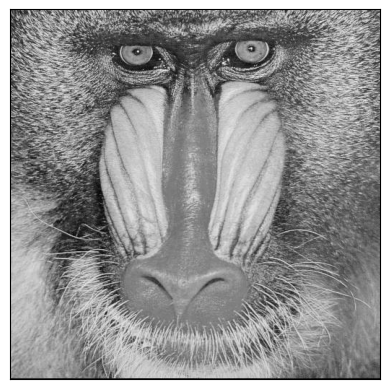

In [4]:
I = cv2.cvtColor(I, cv2.COLOR_RGB2GRAY)
plt.imshow(I, cmap='gray') # tu jesli nie ustawic bedzie wyswietlac w viridis
plt.xticks([]), plt.yticks([])  # to hide tick values on X and Y axis
plt.show()

Czasami konieczne jest zapisanie przetworzonego obrazu.
Służy do tego funkcja `cv2.imwrite`.
Proszę zapisać szarą wersję mandryla w formacie *png*.
Warto sprawdzić, czy obraz zapisał się poprawnie tj. otworzyć go w aplikacji do przeglądania obrazów
lub wczytać ponownie (`cv2.imread('szaryMandryl.png', cv2.IMREAD_GRAYSCALE)`) i porównać z oryginałem (`np.array_equal`).

**Uwaga:** `imwrite` (podobnie jak `imread`) zakłada kolejność kanałów BGR. Zapisanie kolorowego obrazu `I` (już w RGB) zamieniłoby czerwień z niebieskim.
Obraz w skali szarości ma jeden kanał, więc ten problem go nie dotyczy.

In [5]:
cv2.imwrite('szaryMandryl.png', I)

True

In [6]:
I_gray = cv2.imread('szaryMandryl.png', cv2.IMREAD_GRAYSCALE)
np.array_equal(I, I_gray)

True

Obraz w skali szarości możemy traktować jako dwuwymiarową funkcję $L(x,y)$, gdzie $x$, $y$ to współrzędne piksela, a $L(x,y)$ poziom jasności (najczęściej [0;255] - zapis na 8-bitach, typ *unsigned int*).
Wyświetl obraz mandryl jako funkcję dwuwymiarową.
Rysowanie wszystkich $512 \times 512$ punktów trwa kilka sekund, dlatego parametry `rstride` i `cstride` (co który wiersz/kolumna siatki jest rysowany) ustawiamy na 4:

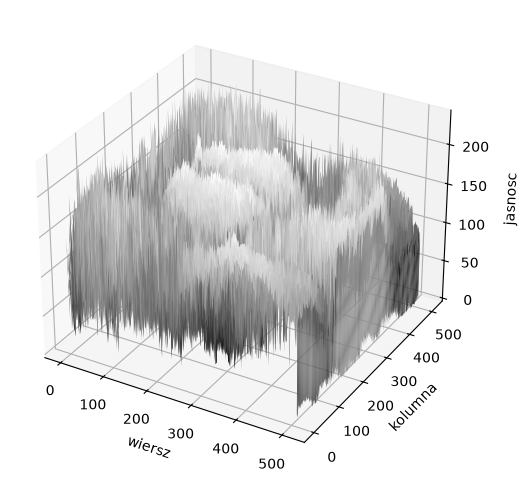

In [7]:
# create grid
xx, yy = np.mgrid[0:I.shape[0], 0:I.shape[1]]

# create the figure
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection = '3d')
ax.plot_surface(xx, yy, I, rstride=4, cstride=4, cmap=plt.get_cmap('gray'),
        linewidth=0)
ax.set_xlabel('wiersz')
ax.set_ylabel('kolumna')
ax.set_zlabel('jasnosc', labelpad=8)

# show it
plt.show()

Komentarz:
- używamy biblioteki do obliczeń *numpy*,
- tworzymy siatkę punktów o rozmiarach takich jak obraz (*shape*),
- rysujemy wykres 3D,
- uwaga na konwencję indeksowania: w tablicy *numpy* pierwszy indeks to **wiersz** (współrzędna pionowa), a drugi to **kolumna** (współrzędna pozioma).
  Zatem piksel o współrzędnych $(x, y)$ w sensie "poziomo, pionowo" to `IG[y, x]`.

Podczas przetwarzania i analizy obrazów przydatne bywają "przekroje" przez obraz, czyli wartości funkcji $L(x,y)$ w przypadku gdy $x$ lub $y$ jest ustalone.
Wykonaj jeden wybrany przekrój w $x$ i $y$ (najlepiej przez interesujący fragment obrazu, np. środek - przekrój przez jednolite tło niewiele pokaże):
- po pierwsze należy pobrać dany wiersz lub kolumnę - np. `S = IG[10,:]` (tu jedenasty wiersz),
- po drugie stworzyć wykres złożony z dwóch subwykresów: `f, (ax1,ax2) = plt.subplots(1,2)`
- dla każdego z nich ustawić tytuł (np. `ax1.set_title('XXX')`) oraz treść `ax1.plot(S)`,
- na koniec całość wyświetlić `plt.show()`.






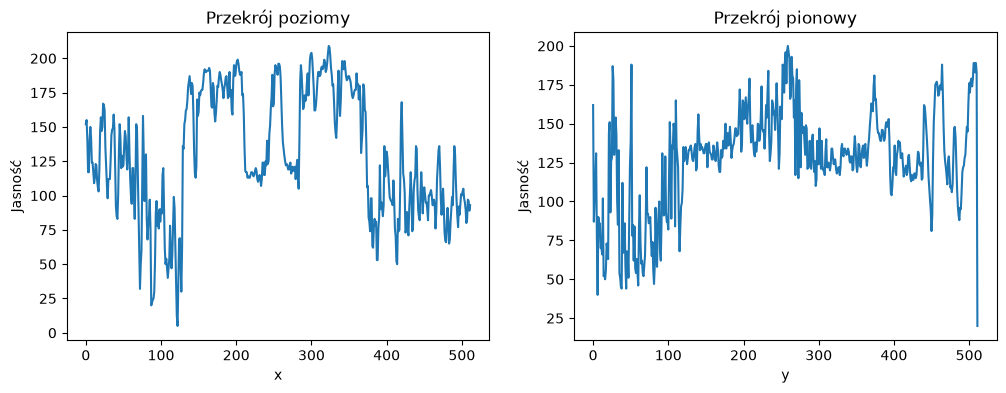

In [8]:
height, width = I.shape

horizontal = I[height // 2, :]
vertical = I[:, width // 2]

f, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.set_title("Przekrój poziomy")
ax1.plot(horizontal)
ax1.set_xlabel("x")
ax1.set_ylabel("Jasność")

ax2.set_title("Przekrój pionowy")
ax2.plot(vertical)
ax2.set_xlabel("y")
ax2.set_ylabel("Jasność")

plt.show()

Obrazy indeksowane składają się z dwóch macierzy - obrazu oraz tzw. mapy kolorów.
W macierzy obrazu zapisane są wartości poszczególnych pikseli.
Macierz mapy kolorów ma rozmiar $m \times 3$ ($m$ wierszy, w każdym 3 wartości - składowe R,G,B).
Podczas wyświetlania, na podstawie wartości piksela, odczytywany jest kolor z macierzy mapy kolorów.
W ten sposób możliwe staje się "pokolorowanie" obrazu w skali szarości (stąd wcześniej szary mandryl był kolorowy -
matplotlib domyślnie używa mapy *viridis*, jeśli nie podamy innej).
Wykorzystanie pseudokoloru nie wpływa na ilość informacji zawartej na obrazku (dane w `IG` pozostają bez zmian), pomaga jedynie przedstawić go w bardziej czytelnej (dla człowieka) formie.
Przykładowo można uzyskać poprawę kontrastu, co jest ważne przy analizie np. obrazów medycznych.
Bardziej obszerny opis i spis dostępnych map można znaleźć w [dokumentacji.](https://matplotlib.org/stable/users/explain/colors/colormaps.html)

Wykorzystując dokumentację oraz polecenie `plt.imshow(IG, cmap=plt.get_cmap('XXX'))` proszę wyświetlić obraz mandryl w 4 różnych mapach kolorów.
Dla każdego obrazu warto dodać pasek kolorów (`plt.colorbar()`), który pokazuje, jaki kolor odpowiada jakiej wartości piksela.

Pytanie: dlaczego mapa *Paired* jest złym wyborem do wizualizacji jasności?

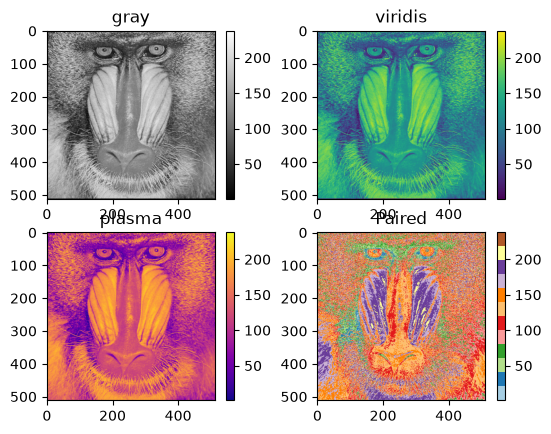

In [9]:
fig , axes = plt.subplots(2, 2)

for ax, name in zip(axes.flat, ['gray', 'viridis', 'plasma', 'Paired']):
    image = ax.imshow(I, cmap=plt.get_cmap(name))
    ax.set_title(name)
    fig.colorbar(image, ax=ax)

plt.show()